# Vanishing Gradient Problem in ANN

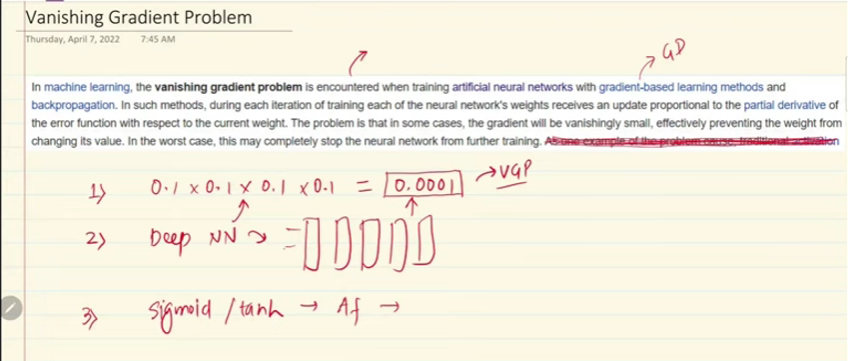

1. It is because of product of derivatives in backpropagation. If the derivatives are small (less than 1), their product can become very small, leading to vanishing gradients.

2. Found in deep neural networks, especially those with many layers.

3. Specially when activation functions like **sigmoid** or **tanh** are used, which can squash the input into a small range, leading to small gradients.

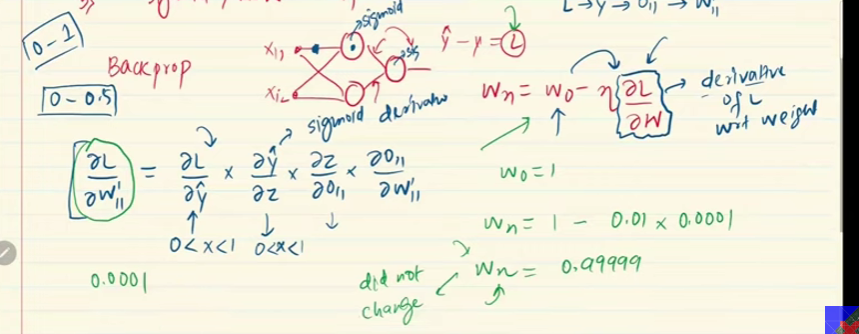

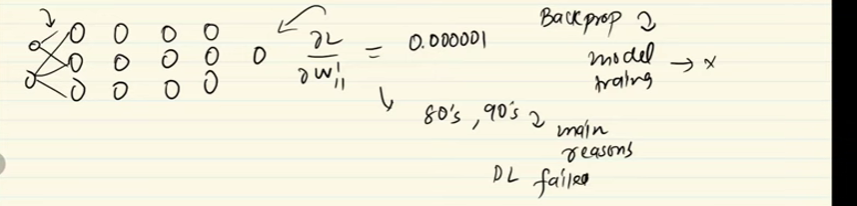

# How to recognize whether a model is suffering from vanishing gradient problem?

- Two ways:

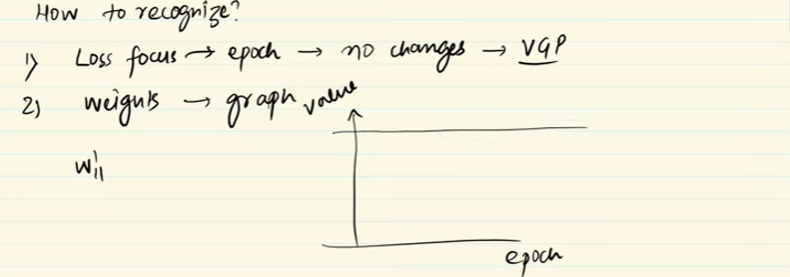


# How to handle vanishing gradient problem?

### 1. Reduce complexity of the model by using fewer layers

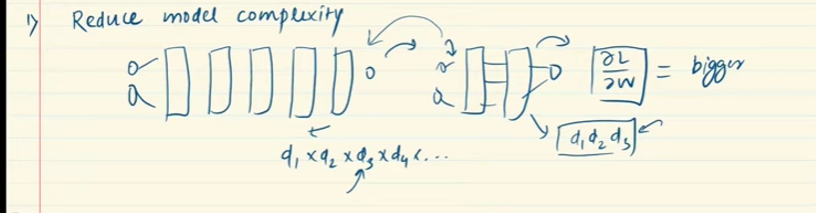

- **This will work but ye utna kaam ka method nhi hai, as we are increasing the complexity of our model to identify complex patterns in data, so reducing the complexity of model is not a good idea.**

### 2. Using activation functions that do not squash the input into a small range, such as ReLU (Rectified Linear Unit) or its variants (Leaky ReLU, Parametric ReLU, etc.). These activation functions allow gradients to flow more easily through the network, mitigating the vanishing gradient problem.

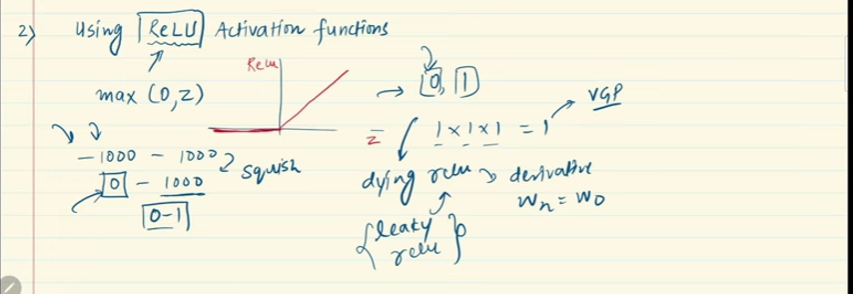

- Derivative of ReLU is 1 for positive inputs, which helps in maintaining a stronger gradient during backpropagation, thus reducing the chances of vanishing gradients.

- But ReLU can suffer from "dying ReLU" problem where neurons can become inactive and only output zero because for negative inputs, the gradient is zero. To mitigate this, variants like Leaky ReLU allow a small, non-zero gradient for negative inputs.

### 3. Proper weight initialization techniques

- Using techniques like Glorot initialization or Xavier initialization can help in maintaining the scale of gradients during backpropagation, reducing the chances of vanishing gradients.

### 4. Using batch normalization

- We will discuss this in later modules, but batch normalization can help in stabilizing the learning process and mitigating the vanishing gradient problem by normalizing the inputs to each layer.

### 5. Using residual networks 

- It is a building block for deep neural networks that allows gradients to flow more easily through the network by introducing skip connections, which can help mitigate the vanishing gradient problem.


# Exploding Gradient Problem

- A similar type of problem where gradients become too large during backpropagation, leading to unstable training. This can be mitigated by techniques such as gradient clipping, which limits the maximum value of gradients during training.

- We will study this in later modules when we will discuss RNNs, as exploding gradients are more common in recurrent neural networks due to their sequential nature.

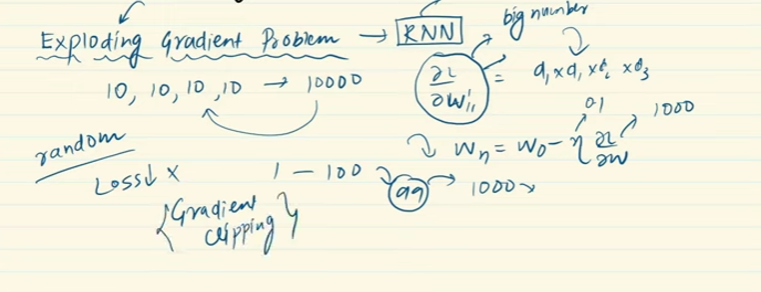

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from keras.layers import Dense
from keras.models import Sequential

In [2]:
X,y = make_moons(n_samples=250, noise=0.05, random_state=42)

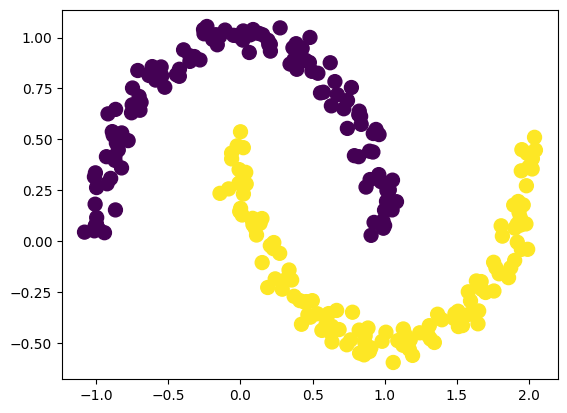

In [3]:
plt.scatter(X[:,0],X[:,1], c=y, s=100)
plt.show()

- ### Model with fewer hidden layers will face fewer vanishing gradient problems

In [4]:
model = Sequential()

model.add(Dense(10,activation='sigmoid',input_dim=2))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [6]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [9]:
model.get_weights()[0]

array([[ 0.39739054, -0.26259392, -0.16482854, -0.46638995, -0.61988777,
         0.24293715, -0.5034068 ,  0.5740045 , -0.21119666,  0.03985286],
       [-0.14133644,  0.68281   ,  0.3746404 ,  0.23607177, -0.5934047 ,
        -0.4116705 ,  0.1705659 , -0.13432115,  0.07950175,  0.09855837]],
      dtype=float32)

In [10]:
old_weights = model.get_weights()[0]

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [12]:
model.fit(X_train, y_train, epochs = 100)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.4900 - loss: 0.7222
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4900 - loss: 0.7150 
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4900 - loss: 0.7103 
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4900 - loss: 0.7054 
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4900 - loss: 0.7019 
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4900 - loss: 0.6996 
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4900 - loss: 0.6974 
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4900 - loss: 0.6958 
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4900 - loss: 0.6941 
Epoch 10/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4900 - loss: 0.6931 
Epoch 11/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4900 - loss: 0.6918 
Epoch 12/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5350 - loss

In [13]:
new_weights = model.get_weights()[0]

In [14]:
model.optimizer.get_config()["learning_rate"]

0.0010000000474974513

In [15]:
gradient = (old_weights - new_weights)/ 0.001
percent_change = abs(100*(old_weights - new_weights)/ old_weights)

In [16]:
gradient

array([[ -435.1573 ,   615.845  ,   628.25415,  -509.87897,   589.39355,
         -618.6086 ,  -415.0779 ,  -547.13696,   644.72345,  -648.0037 ],
       [  866.53357, -1053.6355 ,  -992.566  ,   656.9348 ,  -998.247  ,
         1013.4353 ,   506.90106,  1082.2909 , -1040.479  ,   942.5789 ]],
      dtype=float32)

In [17]:
percent_change

array([[ 109.50369,  234.52371,  381.1562 ,  109.32461,   95.08069,
         254.6373 ,   82.45377,   95.31928,  305.27164, 1625.9907 ],
       [ 613.1    ,  154.30875,  264.93835,  278.27762,  168.22363,
         246.17633,  297.18784,  805.74866, 1308.7499 ,  956.3663 ]],
      dtype=float32)

In [18]:
old_weights

array([[ 0.39739054, -0.26259392, -0.16482854, -0.46638995, -0.61988777,
         0.24293715, -0.5034068 ,  0.5740045 , -0.21119666,  0.03985286],
       [-0.14133644,  0.68281   ,  0.3746404 ,  0.23607177, -0.5934047 ,
        -0.4116705 ,  0.1705659 , -0.13432115,  0.07950175,  0.09855837]],
      dtype=float32)

In [19]:
new_weights

array([[ 0.83254784, -0.87843895, -0.7930827 ,  0.04348902, -1.2092813 ,
         0.86154574, -0.0883289 ,  1.1211414 , -0.85592014,  0.6878566 ],
       [-1.0078701 ,  1.7364457 ,  1.3672065 , -0.4208631 ,  0.40484232,
        -1.4251059 , -0.33633518, -1.216612  ,  1.1199808 , -0.8440206 ]],
      dtype=float32)

- ### Model with more hidden layer will face more vanishing gradient problem

In [32]:
model1 = Sequential()

model1.add(Dense(10,activation='sigmoid',input_dim=2))
model1.add(Dense(10,activation='sigmoid'))
model1.add(Dense(10,activation='sigmoid'))
model1.add(Dense(10,activation='sigmoid'))
model1.add(Dense(10,activation='sigmoid'))
model1.add(Dense(10,activation='sigmoid'))
model1.add(Dense(10,activation='sigmoid'))
model1.add(Dense(10,activation='sigmoid'))
model1.add(Dense(10,activation='sigmoid'))
model1.add(Dense(10,activation='sigmoid'))
model1.add(Dense(10,activation='sigmoid'))
model1.add(Dense(10,activation='sigmoid'))
model1.add(Dense(10,activation='sigmoid'))
model1.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
model1.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [34]:
old_weights = model1.get_weights()[0]

In [35]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [36]:
model1.fit(X_train, y_train, epochs = 100)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.4900 - loss: 0.7326
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4900 - loss: 0.7215 
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4900 - loss: 0.7140
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4900 - loss: 0.7073 
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4900 - loss: 0.7037 
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4900 - loss: 0.6989 
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4900 - loss: 0.6966 
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4900 - loss: 0.6957 
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4900 - loss: 0.6942 
Epoch 10/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4900 - loss: 0.6939 
Epoch 11/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4900 - loss: 0.6932 
Epoch 12/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5100 - loss

In [37]:
new_weights = model1.get_weights()[0]

In [38]:
gradient = (old_weights - new_weights)/ 0.001
percent_change = abs(100*(old_weights - new_weights)/ old_weights)

In [39]:
gradient

array([[ 4.339799  ,  2.3866892 ,  1.7743407 , -6.1312466 ,  0.46875325,
         7.750276  , -1.7579197 ,  1.4090835 , -6.351232  , -1.4306083 ],
       [-3.392443  , -2.112165  , -1.5184878 ,  4.8397183 , -0.29227138,
        -6.1037984 ,  1.6584097 , -1.2045354 ,  6.1179247 ,  1.1584163 ]],
      dtype=float32)

In [40]:
percent_change

array([[ 3.8087406 ,  0.47076073,  0.44639465,  2.8187852 ,  0.62016016,
        11.582646  ,  0.2551963 ,  0.33839566,  1.0213782 ,  4.0732155 ],
       [ 2.1427066 ,  1.2581841 ,  0.30677134,  1.1276326 ,  0.06455152,
         5.149694  ,  0.53139305,  0.48660186,  8.769187  ,  0.6002455 ]],
      dtype=float32)

In [41]:
old_weights

array([[-0.11394316, -0.5069856 , -0.39748254, -0.2175138 , -0.07558584,
         0.06691283,  0.68885   ,  0.4164012 ,  0.6218297 , -0.03512233],
       [-0.15832514, -0.1678741 ,  0.49499017, -0.4291928 , -0.4527723 ,
         0.11852741,  0.31208724, -0.24754024, -0.06976616,  0.19299042]],
      dtype=float32)

In [42]:
new_weights

array([[-0.11828296, -0.5093723 , -0.39925689, -0.21138255, -0.0760546 ,
         0.05916255,  0.6906079 ,  0.41499212,  0.6281809 , -0.03369173],
       [-0.1549327 , -0.16576193,  0.49650866, -0.43403253, -0.45248002,
         0.12463121,  0.31042883, -0.2463357 , -0.07588409,  0.191832  ]],
      dtype=float32)

- ### Changing the activation function to ReLU or its variants can help mitigate the vanishing gradient problem, allowing for deeper networks to be trained effectively.

In [20]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [21]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [22]:
old_weights = model.get_weights()[0]

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [24]:
model.fit(X_train, y_train, epochs = 100)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.4700 - loss: 0.6935
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5850 - loss: 0.6929 
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7200 - loss: 0.6923 
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5250 - loss: 0.6915 
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5100 - loss: 0.6906 
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7150 - loss: 0.6890 
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8900 - loss: 0.6860 
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8400 - loss: 0.6822 
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9200 - loss: 0.6757 
Epoch 10/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9150 - loss: 0.6659 
Epoch 11/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9050 - loss: 0.6510 
Epoch 12/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9450 - loss

In [25]:
new_weights = model.get_weights()[0]

In [26]:
model.optimizer.get_config()["learning_rate"]

0.0010000000474974513

In [27]:
gradient = (old_weights - new_weights)/ 0.001
percent_change = abs(100*(old_weights - new_weights)/ old_weights)

In [28]:
gradient

array([[-106.68295  ,  213.82254  ,  217.98431  ,  -61.37767  ,
         -37.207367 , -226.87576  ,  153.32579  ,    3.3911614,
         131.50479  ,   -7.084965 ],
       [ -46.936592 ,   85.55793  ,  -30.311567 ,  -41.340527 ,
          41.698006 ,  -71.915146 ,  -71.0818   ,   76.17387  ,
        -121.050514 ,  -62.860905 ]], dtype=float32)

In [29]:
percent_change

array([[ 35.35035  ,  31.57105  ,  41.21006  ,  20.296438 , 192.71661  ,
         53.88395  ,  35.09648  ,   1.4642526,  46.04779  ,   2.0108128],
       [ 44.959023 ,  16.26414  ,  14.916622 ,  42.97662  ,  16.168142 ,
         29.128971 ,  78.198105 , 317.9796   ,  76.179016 ,  14.296931 ]],
      dtype=float32)

In [30]:
old_weights

array([[ 0.30178756, -0.67727405, -0.528959  ,  0.30240613,  0.01930678,
        -0.42104515, -0.43686944,  0.23159677, -0.28558332,  0.35234338],
       [-0.10439861,  0.52605265,  0.20320666, -0.09619308, -0.2579023 ,
         0.2468853 ,  0.09089965,  0.02395558, -0.1589027 ,  0.4396811 ]],
      dtype=float32)

In [31]:
new_weights

array([[ 0.4084705 , -0.8910966 , -0.7469433 ,  0.3637838 ,  0.05651415,
        -0.19416939, -0.59019524,  0.2282056 , -0.41708812,  0.35942835],
       [-0.05746201,  0.44049472,  0.23351823, -0.05485255, -0.2996003 ,
         0.31880045,  0.16198145, -0.05221829, -0.03785218,  0.502542  ]],
      dtype=float32)